<a href="https://colab.research.google.com/github/SarthakSaxena6802/bird-species-classification/blob/eda%2Flabel-stats/notebooks/01_eda_verni.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import zipfile
import tarfile
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
zip_path = "/content/multilabel-bird-species-classification-nips2013.zip"

print("Dataset file:", zip_path)
print("File exists:", os.path.exists(zip_path))

Dataset file: /content/multilabel-bird-species-classification-nips2013.zip
File exists: True


In [ ]:
import os
print(os.listdir("/content"))

['.config', 'multilabel-bird-species-classification-nips2013.zip', 'sample_data']


In [ ]:
with zipfile.ZipFile(zip_path, "r") as z:
    zip_contents = z.namelist()

print("Files inside ZIP:")
for name in zip_contents:
    print(name)

label_archives = [
    name for name in zip_contents
    if name.endswith("NIPS4B_BIRD_CHALLENGE_TRAIN_LABELS.tar")
]

assert label_archives, (
    "Label archive not found. Check the ZIP file you uploaded."
)

print("\nLabel archive found:", label_archives[0])


Files inside ZIP:
NIPS4B_BIRD_CHALLENGE_TRAIN_LABELS.tar
NIPS4B_BIRD_CHALLENGE_TRAIN_TEST_MFCC.tar.gz
NIPS4B_BIRD_CHALLENGE_TRAIN_TEST_WAV.tar.gz

Label archive found: NIPS4B_BIRD_CHALLENGE_TRAIN_LABELS.tar


In [ ]:
project_dir = "/content/bird_project"
os.makedirs(project_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    label_archive_name = label_archives[0]
    label_archive_bytes = z.read(label_archive_name)

import io

with tarfile.open(
    fileobj=io.BytesIO(label_archive_bytes),
    mode="r:"
) as tar:
    tar.extractall(path=project_dir)

print("Label files extracted successfully!")


Label files extracted successfully!


/tmp/ipykernel_2340/3574633874.py:14: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=project_dir)


In [ ]:

csv_files = []

for root, dirs, filenames in os.walk(project_dir):
    for filename in filenames:
        if filename.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, filename))

print("CSV files found:")
for path in csv_files:
    print(path)

labels_matches = [
    path for path in csv_files
    if os.path.basename(path).lower() == "numero_file_train.csv"
]

species_matches = [
    path for path in csv_files
    if os.path.basename(path).lower()
    == "nips4b_birdchallenge_espece_list.csv"
]

assert len(labels_matches) == 1, (
    f"Expected one numero_file_train.csv, found {len(labels_matches)}."
)

assert len(species_matches) == 1, (
    f"Expected one species-list CSV, found {len(species_matches)}."
)

labels_path = labels_matches[0]
species_path = species_matches[0]

print("\nLabels file:", labels_path)
print("Species file:", species_path)


CSV files found:
/content/bird_project/NIPS4B_BIRD_CHALLENGE_TRAIN_LABELS/nips4b_birdchallenge_espece_list.csv
/content/bird_project/NIPS4B_BIRD_CHALLENGE_TRAIN_LABELS/numero_file_train.csv
/content/bird_project/NIPS4B_BIRD_CHALLENGE_TRAIN_LABELS/nips4b_birdchallenge_train_labels.csv
/content/bird_project/NIPS4B_BIRD_CHALLENGE_TRAIN_LABELS/example_NIPS4B13_submission_format_test_prediction.csv
/content/bird_project/NIPS4B_BIRD_CHALLENGE_TRAIN_LABELS/tps_canaux_sr_nbits_TRAIN.csv

Labels file: /content/bird_project/NIPS4B_BIRD_CHALLENGE_TRAIN_LABELS/numero_file_train.csv
Species file: /content/bird_project/NIPS4B_BIRD_CHALLENGE_TRAIN_LABELS/nips4b_birdchallenge_espece_list.csv


In [ ]:
df = pd.read_csv(labels_path, header=None)

print("Dataset shape:", df.shape)
display(df.head())

assert df.shape[1] == 89, (
    f"Expected 89 columns, but found {df.shape[1]}. "
    "Check that numero_file_train.csv was loaded."
)

df.columns = (
    ["recording_id"]
    + [f"class_{i}" for i in range(1, 88)]
    + ["duration_seconds"]
)

class_columns = [f"class_{i}" for i in range(1, 88)]

print("Number of recordings:", len(df))
print("Number of sound classes:", len(class_columns))
print("Duration column:", "duration_seconds")


Dataset shape: (687, 89)


,0,1,2,3,4,5,6,7,8,9,...,79,80,81,82,83,84,85,86,87,88
0,1,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5.0039
1,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5.0039
2,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5.0039
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,5.0039
4,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,5.0039


Number of recordings: 687
Number of sound classes: 87
Duration column: duration_seconds


In [ ]:
species = pd.read_csv(species_path)

species.columns = [
    str(col).strip().lower().replace(" ", "_")
    for col in species.columns
]

print("Species dictionary columns:")
print(species.columns.tolist())

display(species.head(10))


Species dictionary columns:
['class_number', 'class_name', 'english_name', 'scientific_name', 'type']


,class_number,class_name,english_name,scientific_name,type
0,none,Empty,Empty,noise sample,noise
1,1,Aegcau_call,Long-tailed Tit,Aegithalos caudatus,bird
2,2,Alaarv_song,Eurasian Skylark,Alauda arvensis,bird
3,3,Anttri_song,Tree Pipit,Anthus trivialis,bird
4,4,Butbut_call,Common Buzzard,Buteo buteo,bird
5,5,Carcan_call,Common Linnet,Linaria cannabina,bird
6,6,Carcan_song,Common Linnet,Linaria cannabina,bird
7,7,Carcar_call,European Goldfinch,Carduelis carduelis,bird
8,8,Carcar_song,European Goldfinch,Carduelis carduelis,bird
9,9,Cerbra_call,Short-toed Treecreeper,Certhia brachydactyla,bird


In [ ]:
df[class_columns] = df[class_columns].apply(
    pd.to_numeric, errors="raise"
)

df["duration_seconds"] = pd.to_numeric(
    df["duration_seconds"], errors="raise"
)

# Check for missing or invalid data.
assert df["recording_id"].notna().all(), "Missing recording IDs."

assert df[class_columns].notna().all().all(), (
    "Missing class labels found. Inspect the original CSV."
)

assert df[class_columns].isin([0, 1]).all().all(), (
    "Invalid class values found. Labels must be 0 or 1."
)

assert df["duration_seconds"].notna().all(), "Missing clip durations."

assert (df["duration_seconds"] >= 0).all(), (
    "Negative clip durations found."
)

print("All validation checks passed!")
print("Dataset shape:", df.shape)
print("Unique recording IDs:", df["recording_id"].nunique())


All validation checks passed!
Dataset shape: (687, 89)
Unique recording IDs: 687


In [ ]:
assert "class_number" in species.columns, (
    "The dictionary needs a 'class number' column."
)
assert "class_name" in species.columns, (
    "The dictionary needs a 'class name' column."
)
assert "type" in species.columns, (
    "The dictionary needs a 'type' column."
)

species["class_number"] = pd.to_numeric(
    species["class_number"], errors="coerce"
)

species_map = species.dropna(subset=["class_number"]).copy()
species_map["class_number"] = species_map["class_number"].astype(int)

assert set(species_map["class_number"]) == set(range(1, 88)), (
    "Expected class IDs 1 through 87 in the species dictionary."
)

name_map = dict(zip(
    species_map["class_number"],
    species_map["class_name"].astype(str).str.strip()
))

type_map = dict(zip(
    species_map["class_number"],
    species_map["type"].astype(str).str.strip().str.lower()
))

counts = df[class_columns].sum()

result = pd.DataFrame({
    "class_number": range(1, 88),
    "class_name": [name_map[i] for i in range(1, 88)],
    "type": [type_map[i] for i in range(1, 88)],
    "recording_count": [
        int(counts[f"class_{i}"]) for i in range(1, 88)
    ]
})

result = result.sort_values(
    ["recording_count", "class_name"],
    ascending=[True, True]
).reset_index(drop=True)

display(result)


,class_number,class_name,type,recording_count
0,16,Colpal_song,bird,7
1,68,Siteur_call,bird,7
2,17,Corcor_call,bird,8
3,31,Hirrus_call,bird,8
4,32,Jyntor_song,bird,8
...,...,...,...,...
82,23,Erirub_song,bird,20
83,44,Parate_song,bird,20
84,47,Parmaj_call,bird,20
85,49,Pasdom_call,bird,20


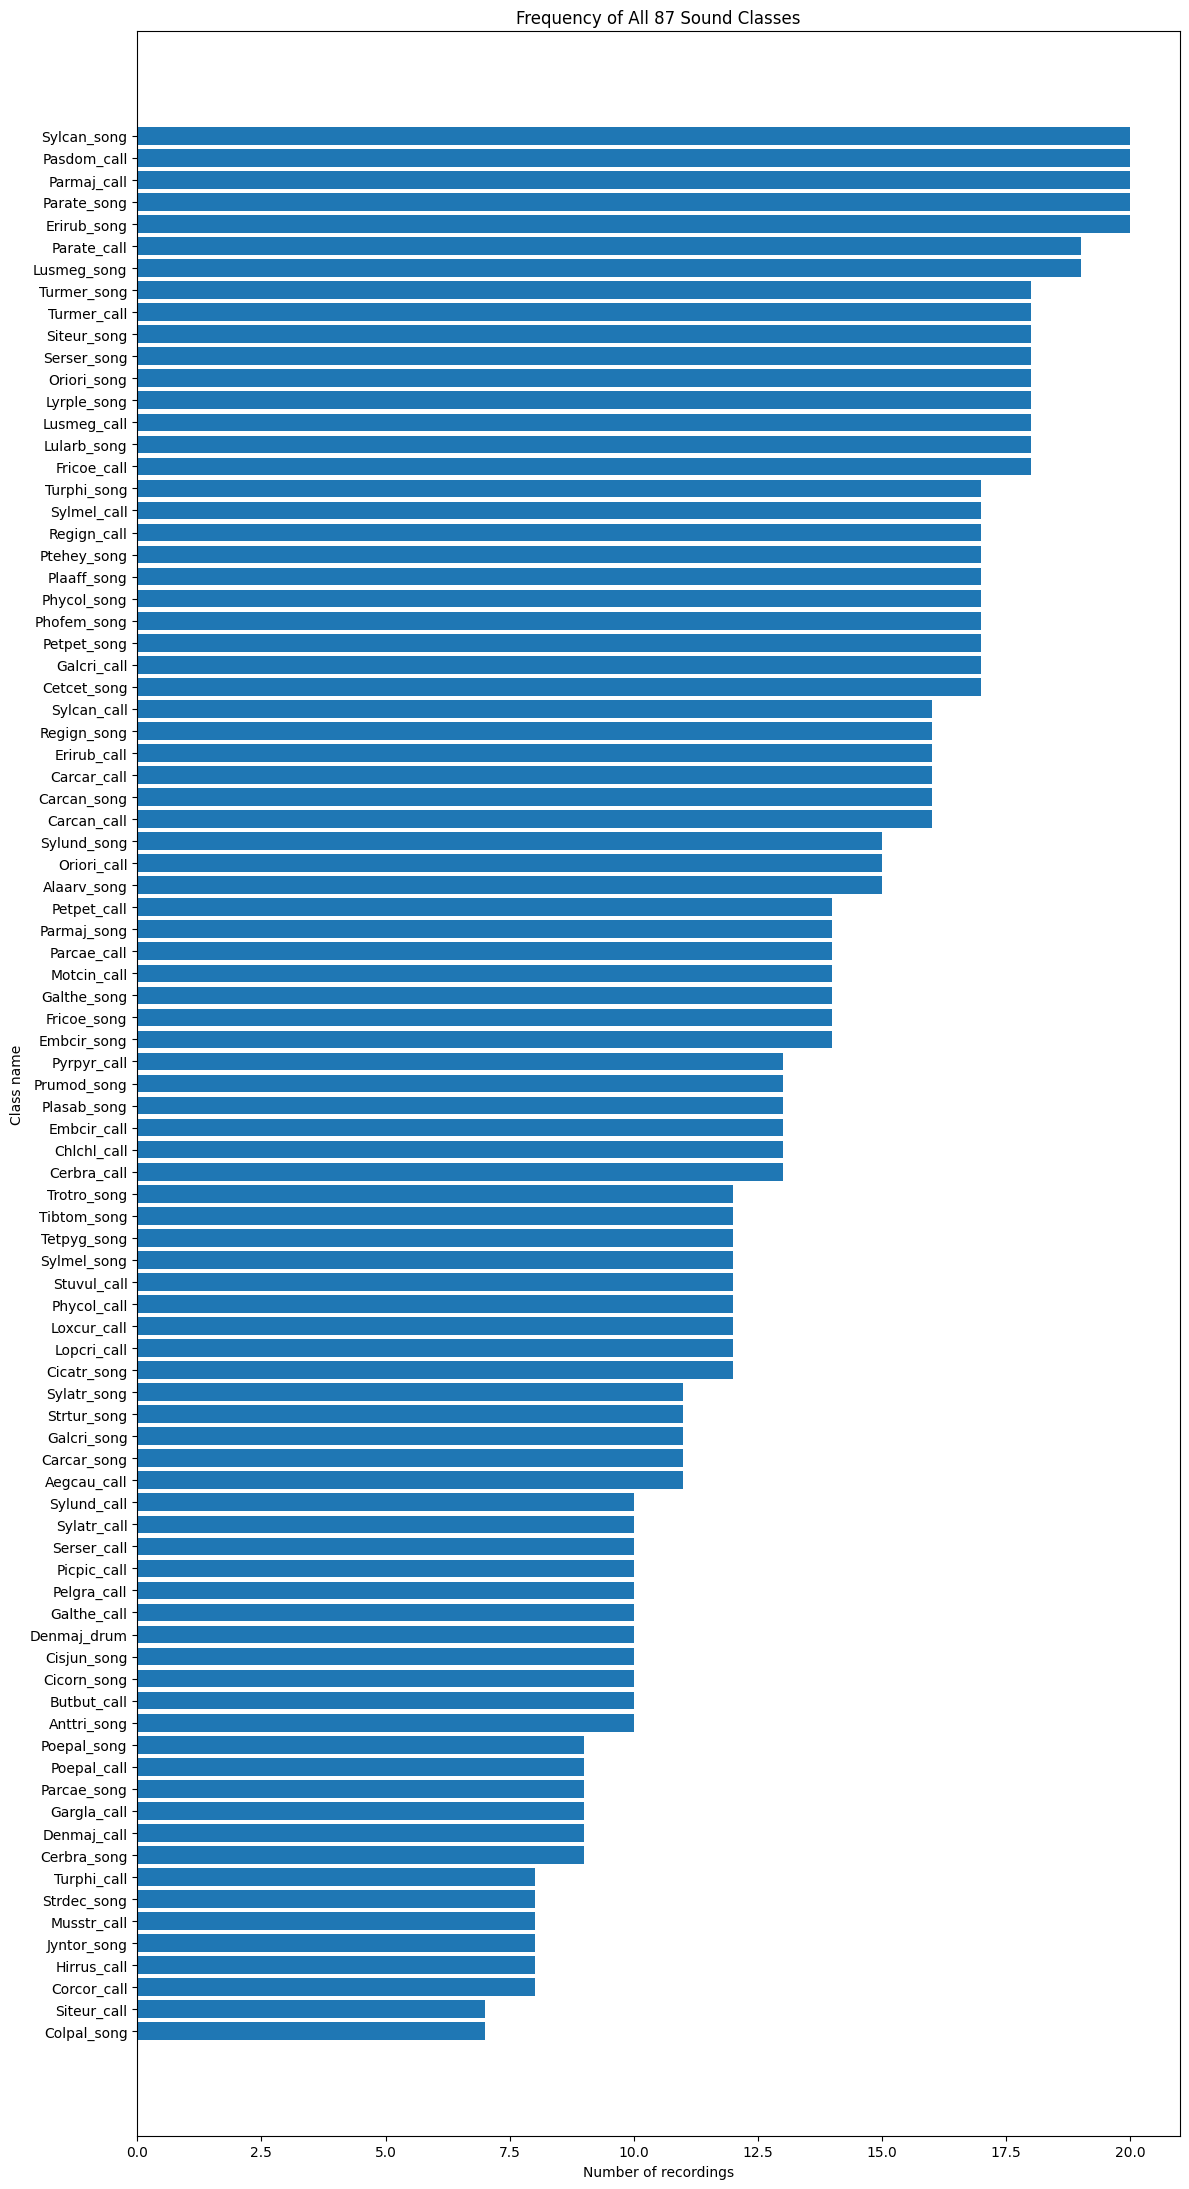

In [ ]:
plt.figure(figsize=(12, 22))

plt.barh(
    result["class_name"],
    result["recording_count"]
)

plt.xlabel("Number of recordings")
plt.ylabel("Class name")
plt.title("Frequency of All 87 Sound Classes")
plt.tight_layout()
plt.show()


Total clips: 687
Clips with zero positive labels: 100
Clips with one or more labels: 587


,number_of_clips
number_of_labels,
0,100
1,230
2,195
3,114
4,32
5,10
6,6


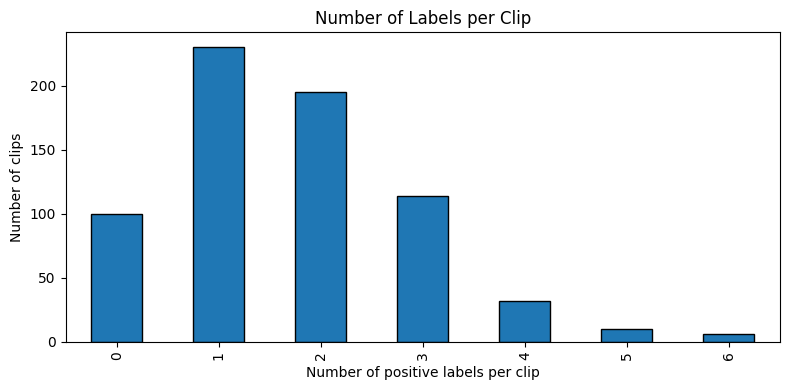

In [ ]:

df["number_of_labels"] = df[class_columns].sum(axis=1)

empty_clips = int((df["number_of_labels"] == 0).sum())
clips_with_labels = int((df["number_of_labels"] > 0).sum())

print("Total clips:", len(df))
print("Clips with zero positive labels:", empty_clips)
print("Clips with one or more labels:", clips_with_labels)

display(
    df["number_of_labels"]
    .value_counts()
    .sort_index()
    .rename_axis("number_of_labels")
    .to_frame("number_of_clips")
)

df["number_of_labels"].value_counts().sort_index().plot(
    kind="bar", figsize=(8, 4), edgecolor="black"
)
plt.xlabel("Number of positive labels per clip")
plt.ylabel("Number of clips")
plt.title("Number of Labels per Clip")
plt.tight_layout()
plt.show()


Clip duration statistics (seconds):


,duration_seconds
count,687.000000
mean,4.230155
std,1.147231
min,1.015900
25%,3.094100
50%,5.003900
75%,5.003900
max,5.003900


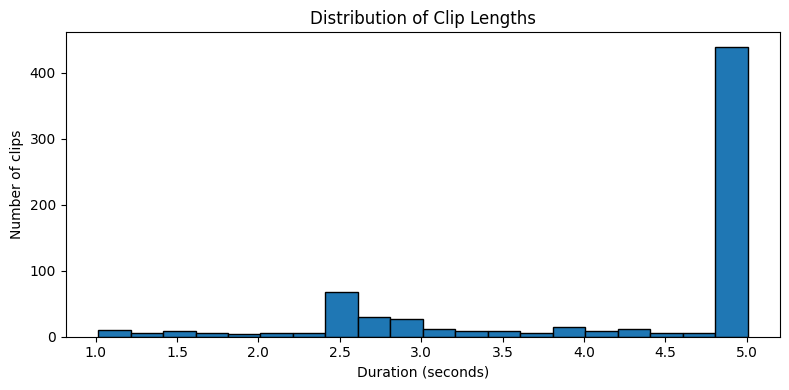

In [ ]:

print("Clip duration statistics (seconds):")
display(df["duration_seconds"].describe())

plt.figure(figsize=(8, 4))
plt.hist(df["duration_seconds"], bins=20, edgecolor="black")
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of clips")
plt.title("Distribution of Clip Lengths")
plt.tight_layout()
plt.show()


Positive class labels by category:


,positive_label_count
type,
amphibian,10
bird,1038
insect,128


Recordings containing each category:


,recordings_with_category
bird,557
insect,103
amphibian,10


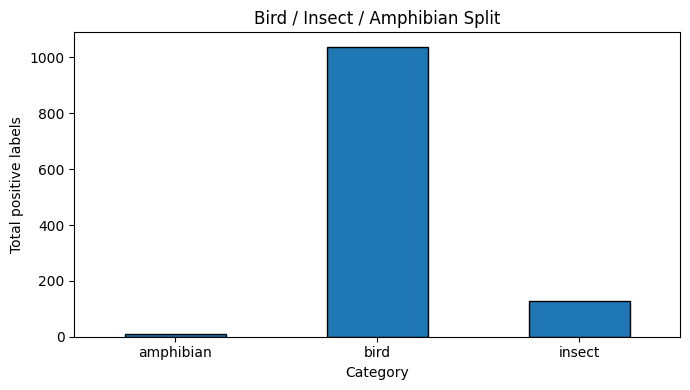

In [ ]:

result["type"] = result["type"].str.strip().str.lower()

# Total positive labels for each category
category_labels = result.groupby("type")["recording_count"].sum()

print("Positive class labels by category:")
display(category_labels.to_frame("positive_label_count"))

# Number of recordings containing at least one class of each type
category_clip_counts = {}

for category in ["bird", "insect", "amphibian"]:
    ids = result.loc[
        result["type"] == category, "class_number"
    ].tolist()

    cols = [f"class_{i}" for i in ids]

    category_clip_counts[category] = (
        int((df[cols].sum(axis=1) > 0).sum()) if cols else 0
    )

print("Recordings containing each category:")
display(
    pd.Series(
        category_clip_counts,
        name="recordings_with_category"
    ).to_frame()
)

category_labels.plot(kind="bar", figsize=(7, 4), edgecolor="black")
plt.xlabel("Category")
plt.ylabel("Total positive labels")
plt.title("Bird / Insect / Amphibian Split")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

result.to_csv("/content/bird_class_counts.csv", index=False)
df.to_csv("/content/bird_clip_summary.csv", index=False)

print("Results saved successfully!")

from google.colab import files
files.download("/content/bird_class_counts.csv")
files.download("/content/bird_clip_summary.csv")


Results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

least = result.iloc[0]
most = result.iloc[-1]

print("========== FINDINGS ==========")
print(f"1. Total recordings: {len(df)}")
print(f"2. Total sound classes: {len(class_columns)}")
print(f"3. Clips with zero positive labels: {empty_clips}")
print(f"4. Clips with positive labels: {clips_with_labels}")
print(
    f"5. Duration range: {df['duration_seconds'].min():.2f} to "
    f"{df['duration_seconds'].max():.2f} seconds"
)
print(
    f"6. Least frequent class: {least['class_name']} "
    f"({least['recording_count']} recordings)"
)
print(
    f"7. Most frequent class: {most['class_name']} "
    f"({most['recording_count']} recordings)"
)

for category, count in category_clip_counts.items():
    print(
        f"8. {category.capitalize()}: {count} recordings "
        "contain at least one class in this category."
    )

print("9. One clip may have multiple positive labels.")
print("==============================")


========== FINDINGS ==========
1. Total recordings: 687
2. Total sound classes: 87
3. Clips with zero positive labels: 100
4. Clips with positive labels: 587
5. Duration range: 1.02 to 5.00 seconds
6. Least frequent class: Colpal_song (7 recordings)
7. Most frequent class: Sylcan_song (20 recordings)
8. Bird: 557 recordings contain at least one class in this category.
8. Insect: 103 recordings contain at least one class in this category.
8. Amphibian: 10 recordings contain at least one class in this category.
9. One clip may have multiple positive labels.
